In [1]:
#need initial file path of dataset
file_path = r"C:\Users\jbosb\OneDrive\Documents\Hopkins_Studies\Applied_Machine_Learning" #folder path of dataset images


In [2]:
import os #need that for path handling
print(os.path.exists(file_path)) #check that path exists
print(os.listdir(file_path)) #check that path contains files

True
['1-s2.0-S0893608005800231-main.pdf', 'appendix_d_calculus.pdf', 'Assignment01_ml.pdf', 'Assignment02_ml.pdf', 'Assignment03_ml.pdf', 'Assignment04_ml.pdf', 'Assignment05_ml.pdf', 'Assignment06_ml.pdf', 'Assignment07_ml.pdf', 'Assignment08_ml.pdf', 'Assignment09_ml.pdf', 'Assignment10_ml.pdf', 'Assignment11_ml.pdf', 'Assignment12_ml.pdf', 'Assignment13_ml.pdf', 'Automatic_differentation.pdf', 'breast_cancer_preprocessed.csv', 'breast_cancer_raw.csv', 'cats_dogs.7z', 'ch11.ipynb', 'clustering_synthetic_dataset.csv', 'creditcard.csv', 'creditcard.csv.zip', 'disinformation.7z', 'GeneratedLabelledFlows.7z', 'heart_dataset.csv', 'mistakes.png', 'mnist.7z', 'seg_pred', 'seg_pred.zip', 'seg_test', 'seg_test.zip', 'seg_train', 'seg_train.zip', 'stack_overflow_data.7z', 'store_data.csv', 'titanic_preprocessed.csv', 'Vanishing_gradient.pdf']


Part 1: Download the dataset. Unzip and explore the file folders. Load the image dataset 
with training and testing grouped. (Note, cv2 reads and saves in BGR channel order) 



In [3]:
import cv2 #need for handling images


IMGSIZE = (128, 128) 
CNAMES = ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street'] 
X_tr, y_tr, X_ts, y_ts = [], [], [], [] 
for label in CNAMES: 
    path = os.path.join(file_path, 'seg_train', 'seg_train', label)
    for f in sorted([_ for _ in os.listdir(path) if _.lower().endswith('.jpg')]):
        X_tr += [cv2.resize(cv2.imread(os.path.join(path,f)), IMGSIZE)] 
        y_tr += [CNAMES.index(label)] 

In [4]:
#checking the number of chanels in the images
print(X_tr[0].shape)

(128, 128, 3)


Three channels for BGR. Need to check whole dataset shape.

In [5]:
import numpy as np
X_tr_np = np.array(X_tr)
print(X_tr_np.shape)

(14034, 128, 128, 3)


Need to display like 5 images from each folder.

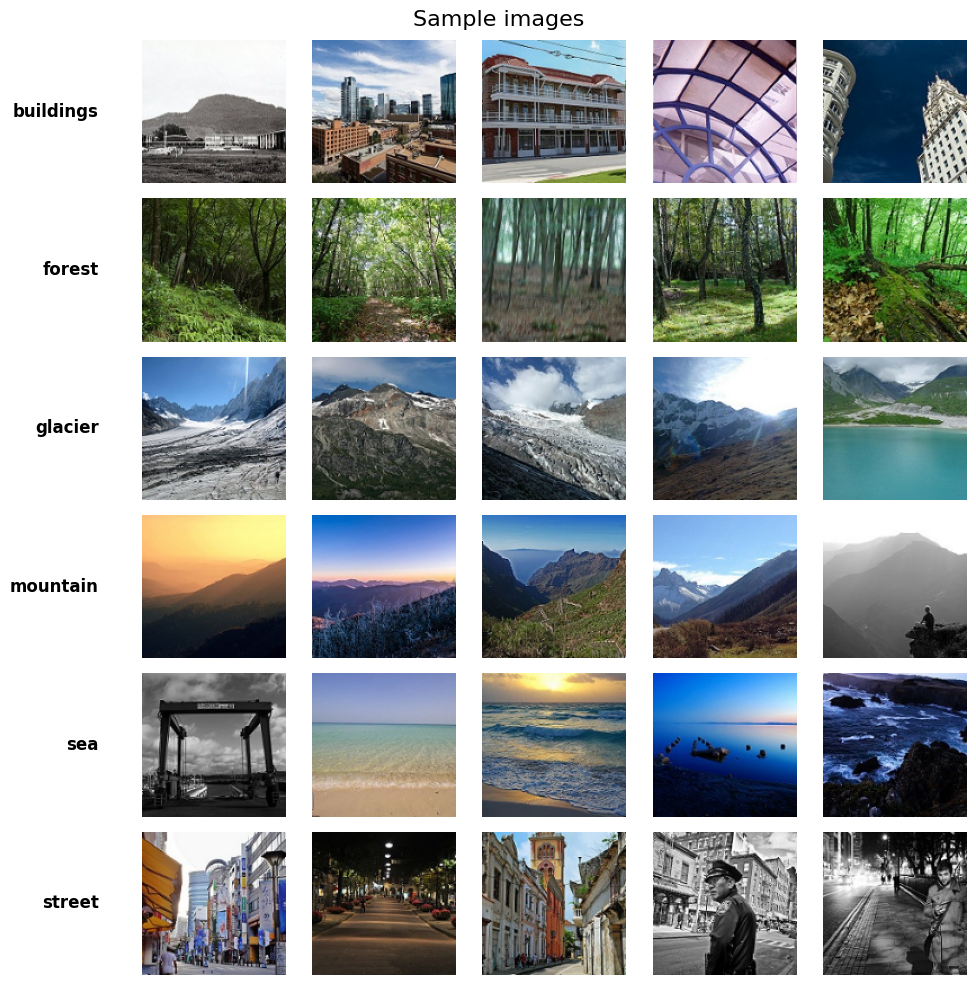

In [6]:
import matplotlib.pyplot as plt 

fig, ax = plt.subplots(6,5, figsize=(10,10)) #create a 6x5 grid of images

for row, cname in enumerate(CNAMES):
    class_index = [i for i, y in enumerate(y_tr) if y == CNAMES.index(cname)] #get indices of images for this class

    for col in range(5): 
        idx = class_index[col] #get index of image to display
        img = cv2.cvtColor(X_tr[idx], cv2.COLOR_BGR2RGB) #convert from BGR to RGB for display
        ax[row, col].imshow(img) #display the image
        ax[row, col].axis('off') #hide axes
    
    ax[row, 0].text(-.3, 0.5, cname,
                    fontsize=12,
                    fontweight='bold',
                    transform=ax[row, 0].transAxes,
                    va='center',
                    ha='right',)


plt.suptitle("Sample images", fontsize=16)
plt.tight_layout()
plt.show()


Part 1: Download the dataset. Unzip and explore the file folders. Load the image dataset 
with training and testing grouped. (Note, cv2 reads and saves in BGR channel order) 

Okay printed out some samples from the training set.

In [7]:
#will scale the images to [0,1]
for i, channel in enumerate(['Blue', 'Green', 'Red']): #cv2 is BGR order
    print(f"Channel {channel}: min={X_tr_np[:,:,:,i].min()}, max={X_tr_np[:,:,:,i].max()}")

Channel Blue: min=0, max=255
Channel Green: min=0, max=255
Channel Red: min=0, max=255


In [8]:
#to scale from [0,1] we divide the pixel values by 255
X_tr_scaled = X_tr_np / 255.0
for i, channel in enumerate(['Blue', 'Green', 'Red']): 
    print(f"Channel {channel} after scaling: min={X_tr_scaled[:,:,:,i].min()}, max={X_tr_scaled[:,:,:,i].max()}")
print(X_tr_scaled.shape)

#so we have scaled everything 

Channel Blue after scaling: min=0.0, max=1.0
Channel Green after scaling: min=0.0, max=1.0
Channel Red after scaling: min=0.0, max=1.0
(14034, 128, 128, 3)


Part 2:  Convert the imageset to numpy array, such as the array size: 
(14034, 128, 128, 3) 

Took care of that with these lines:
import numpy as np
X_tr_np = np.array(X_tr)

X_tr_scaled = X_tr_np / 255.0
for i, channel in enumerate(['Blue', 'Green', 'Red']): 
    print(f"Channel {channel} after scaling: min={X_tr_scaled[:,:,:,i].min()}, max={X_tr_scaled[:,:,:,i].max()}")
print(X_tr_scaled.shape)

Images are scaled 0 -> 1.

Create a neural network to train and report its performance on the testing portion of 
the dataset. 60% reclassification and 55% testing performance should be achievable 
without any hyperparameter tuning. (Hint: My model with 3 hidden layers of 50 nodes per 
layer, which is similar to the model in module notebook, took around 5 minutes to train 200 
epochs.) 
Reminder, you have to convert the 3D image (including the color channel) to a linear vector 
in case you use fully connected layers at the input, i.e., 

_X = torch.flatten(_X, start_dim=1) 

(Hint, for debugging use print statements or PyCharm to display the tensor shapes) 

In [9]:
#lets use PyTorch to build my first NN for this dataset, need torchvision as well
import torch
import torch.nn as nn #need that for building the neural network
import torchvision
import torchvision.transforms as transforms #need that for data augmentation and normalization

#need three hiden layers, 50 units each, output layer with 6 units, use ReLU activation, and softmax for output


class Trial(nn.Module):
    def __init__(self):
        super(Trial, self).__init__()
        self.flatten = nn.Flatten() #to flatten the 3D image into a 1D vector
        self.fc1 = nn.Linear(128*128*3, 50) #input layer to first hidden layer
        self.relu1 = nn.ReLU() #activation for first hidden layer
        self.fc2 = nn.Linear(50, 50) #first hidden layer to second hidden layer
        self.relu2 = nn.ReLU() #activation for second hidden layer
        self.fc3 = nn.Linear(50, 50) #second hidden layer to third hidden layer
        self.relu3 = nn.ReLU() #activation for third hidden layer
        self.output = nn.Linear(50, 6) #third hidden layer to output layer
        self.dropout = nn.Dropout(0.1) #dropout layer for regularization

    def forward(self, x):
        x = self.flatten(x) 
        x = self.dropout(self.relu1(self.fc1(x))) 
        x = self.dropout(self.relu2(self.fc2(x))) 
        x = self.dropout(self.relu3(self.fc3(x)))        
        x = self.output(x) 
        return x

print(Trial())

Trial(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (fc1): Linear(in_features=49152, out_features=50, bias=True)
  (relu1): ReLU()
  (fc2): Linear(in_features=50, out_features=50, bias=True)
  (relu2): ReLU()
  (fc3): Linear(in_features=50, out_features=50, bias=True)
  (relu3): ReLU()
  (output): Linear(in_features=50, out_features=6, bias=True)
  (dropout): Dropout(p=0.1, inplace=False)
)


Okay we built a basic NN, need to define the loop. Plan on 200 epochs.

In [10]:
#lets setup our criterion and optimizer
import torch.optim as optim

criterion = nn.CrossEntropyLoss()
net = Trial()
optimizer = optim.SGD(net.parameters(), lr=0.001, momentum=0.9) #used SGD to start with, will try with Adam later

In [11]:
from torch.utils.data import TensorDataset, DataLoader

# Convert numpy arrays to PyTorch tensors
X_tr_tensor = torch.tensor(X_tr_scaled, dtype=torch.float32).permute(0, 3, 1, 2)  # (N, 3, 128, 128)
y_tr_tensor = torch.tensor(y_tr, dtype=torch.long)

# Load the test set too
X_ts, y_ts = [], []
for label in CNAMES:
    path = os.path.join(file_path, 'seg_test', 'seg_test', label)
    for f in sorted([_ for _ in os.listdir(path) if _.lower().endswith('.jpg')]):
        X_ts += [cv2.resize(cv2.imread(os.path.join(path, f)), IMGSIZE)]
        y_ts += [CNAMES.index(label)]

X_ts_np = np.array(X_ts) / 255.0
X_ts_tensor = torch.tensor(X_ts_np, dtype=torch.float32).permute(0, 3, 1, 2)
y_ts_tensor = torch.tensor(y_ts, dtype=torch.long)

# Create DataLoaders
trainset = TensorDataset(X_tr_tensor, y_tr_tensor)
testset = TensorDataset(X_ts_tensor, y_ts_tensor)

trainloader = DataLoader(trainset, batch_size=32, shuffle=True)
testloader = DataLoader(testset, batch_size=32, shuffle=False)

In [12]:
losses = []

for epoch in range(200):
    running_loss = 0.0
    for i, data in enumerate(trainloader, 0):
        inputs, labels = data #get the inputs and labels from the dataloader

        optimizer.zero_grad() #zero the parameter gradients

        outputs = net(inputs) #get the outputs from the network
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    # print loss every epoch instead of every 2000 batches
    print(f'Epoch [{epoch + 1}/200] loss: {running_loss / len(trainloader):.3f}') #print average loss for the epoch
    losses.append(running_loss / len(trainloader)) #store the loss for plotting later
print('Finished Training')

Epoch [1/200] loss: 1.594
Epoch [2/200] loss: 1.376
Epoch [3/200] loss: 1.310
Epoch [4/200] loss: 1.257
Epoch [5/200] loss: 1.230
Epoch [6/200] loss: 1.199
Epoch [7/200] loss: 1.174
Epoch [8/200] loss: 1.148
Epoch [9/200] loss: 1.135
Epoch [10/200] loss: 1.119
Epoch [11/200] loss: 1.107
Epoch [12/200] loss: 1.090
Epoch [13/200] loss: 1.074
Epoch [14/200] loss: 1.058
Epoch [15/200] loss: 1.047
Epoch [16/200] loss: 1.042
Epoch [17/200] loss: 1.024
Epoch [18/200] loss: 1.016
Epoch [19/200] loss: 1.006
Epoch [20/200] loss: 0.997
Epoch [21/200] loss: 0.986
Epoch [22/200] loss: 0.973
Epoch [23/200] loss: 0.969
Epoch [24/200] loss: 0.959
Epoch [25/200] loss: 0.946
Epoch [26/200] loss: 0.940
Epoch [27/200] loss: 0.921
Epoch [28/200] loss: 0.926
Epoch [29/200] loss: 0.913
Epoch [30/200] loss: 0.906
Epoch [31/200] loss: 0.895
Epoch [32/200] loss: 0.898
Epoch [33/200] loss: 0.864
Epoch [34/200] loss: 0.877
Epoch [35/200] loss: 0.862
Epoch [36/200] loss: 0.872
Epoch [37/200] loss: 0.851
Epoch [38/

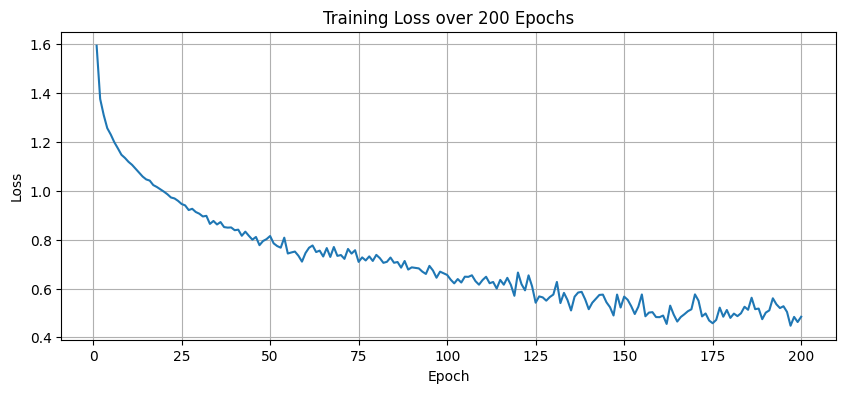

In [13]:
epochs = list(range(1, 201))


plt.figure(figsize=(10, 4))
plt.plot(epochs, losses)
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training Loss over 200 Epochs')
plt.grid(True)
plt.show()

In [14]:
# Checking tensor shapes
print(f"X_tr_tensor shape: {X_tr_tensor.shape}")
print(f"y_tr_tensor shape: {y_tr_tensor.shape}")
print(f"X_ts_tensor shape: {X_ts_tensor.shape}")
print(f"y_ts_tensor shape: {y_ts_tensor.shape}")

# Checking single batch
dataiter = iter(trainloader)
images, labels = next(dataiter)
print(f"Batch image shape: {images.shape}")
print(f"Batch label shape: {labels.shape}")

# Check the output shape
outputs = net(images)
print(f"Network output shape: {outputs.shape}")

X_tr_tensor shape: torch.Size([14034, 3, 128, 128])
y_tr_tensor shape: torch.Size([14034])
X_ts_tensor shape: torch.Size([3000, 3, 128, 128])
y_ts_tensor shape: torch.Size([3000])
Batch image shape: torch.Size([32, 3, 128, 128])
Batch label shape: torch.Size([32])
Network output shape: torch.Size([32, 6])


In [15]:
#Training/reclassification accuracy
correct, total = 0, 0
with torch.no_grad():
    for inputs, labels in trainloader:
        outputs = net(inputs)
        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()
print(f'Training Accuracy: {100 * correct / total:.2f}%')

#Test accuracy
correct, total = 0, 0
with torch.no_grad():
    for inputs, labels in testloader:
        outputs = net(inputs)
        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()
print(f'Testing Accuracy: {100 * correct / total:.2f}%')

Training Accuracy: 86.06%
Testing Accuracy: 55.13%


Part 4: Research and find out how to improve the neural network model to solve this 
problem. Outline an approach.

Techniques available: Dropout, rotating of images, try different optimizers, experiment with different network architectures (extra layers, wider layer)

Initial approach: optimize current network without changing optimizers, alter the current network in terms of layers and width of each layer. Following optimizing the base network, attempt neuron dropout. Keep the images the same until that point and then introduce dataset augmentation in the form of rotating the images. 


100 units per hidden layer
Training Accuracy: 99.36%
Testing Accuracy: 60.97%

50 units per hidden layer
Training Accuracy: 98.13%
Testing Accuracy: 57.37%

Adding in 4th dramatically decreased initial loss, layer had 50 units, training takes similar time frame, but it's not really learning much after the initial epochs
Training Accuracy: 98.09%
Testing Accuracy: 56.60%
No significant improvements, revert back to 3 hidden layers

Keep three hidden layers at 50 units, move onto dropout changes.

Dropout at 0.3 causes much slower training, loss declines slower, more stable at later epochs
Training Accuracy: 69.70%
Testing Accuracy: 49.83%

Changing Dropout to 0.1, with only 50 units dropping out 30% of the neurons may be too much
Training Accuracy: 85.00%
Testing Accuracy: 55.37%



#Improvement strategy - start with base network and optimze it then move to training data

Initial network of three hidden layers of 50 units trained in about 5 min and had a training accuracy/reclassification score of ~99% but only a testing accuracy of ~59% showing significant overfitting. I would want to first determine the optimal base network architecture and then start changing parameters and optimizers to optimize that architecture. We can isolate the contribution to the learning in the network and make changes in a stepwise fashion.

Once the optimal architecture has been been determined we can add in neuron dropout because that addresses a root issue of regularization. I want to make sure the network is solid before I start changing how it learns by adding in neuron dropout. Given that we have only 50 units in each hidden layer I would start with a Dropout rate of 0.1 (10%), if the dropout is too high the network will be unable to effectively learn.

After optimizing dropout settings we can test the optimizers and see if Adam or RMSprop will give us better convergence.

Finally we can try working with dataset itself, for image classification it is suggested that images be rotated randomly that way the model is forced to learn features that are not dependent on orientation of the image. That should help with generalization of the dataset.





